# Assignment 2 — Word Vectors, Neural Networks and Language Models

**344.175 Natural Language Processing — Exercise Track**
Total points: **50** · Deadline: *26.11.2026 10:00*

---

## What you will build

Assignment 1 classified memes by counting words. Here you test whether learned representations
and models do better, on the same memes and the same splits:

```
word vectors (PPMI, fastText) → one vector per meme → logistic regression, neural network
word counts → one n-gram language model per class → classifier
```

Every model goes into one leaderboard next to the Assignment 1 bag of words, with accuracy and
AUROC. The assignment covers Lectures 2 to 4; fastText is explained where it is used. Like
Assignment 1, it uses the text of the **Hateful Memes** dataset only; Assignments 3 and 4 add the pictures.

## Content warning

The dataset contains real hateful content: racism, sexism, religious hatred, slurs and attacks
on people with disabilities, and some of the examples this notebook prints are offensive. Use
the data only for this course and do not redistribute it.

## Where and how to work

You work in teams of two and hand in **one** notebook per team, named with both matriculation
numbers: `assignment_02_<matriculation 1>_<matriculation 2>.ipynb`, for example
`assignment_02_01234567_12345678.ipynb` (leading zeros included). One of you uploads it in
Moodle, and both of you get the grade.

- **Google Colab:** *File → Upload notebook* (the notebook from the ZIP), then *File → Rename*.
  Create a folder `data` in the file panel and upload `assignment_02/data/fasttext_memes.npz`
  from the ZIP into it. The setup cell installs what Colab is missing, and the remaining data is
  downloaded for you. A CPU runtime is enough.
- **Your own computer:** follow `SETUP.md` (`uv sync`, then `uv run jupyter lab`), then
  *File → Save Notebook As…*.

Go through the notebook from top to bottom. Replace every `### YOUR CODE HERE` /
`raise NotImplementedError()` with your own code and run the test cell below it:
`Task N.N passed` means the public tests pass. Before submitting, restart the kernel, run all
cells, and run the submission check at the end.

## Rules

The notebook is graded by a program that runs it and calls your functions by name.

- Do not rename functions or change their parameters.
- Do not add to, remove or modify the given cells; the grader restores them before grading.
  You may add your own cells for experiments.
- Do not import extra packages; the grader has only what `pyproject.toml` installs.
- The notebook must run from a fresh kernel without errors. A crash costs every point after it.

## Grading

```
your points = coding points (0-50) × average of the two written weights (0.0-1.0)
```

**Coding tasks: 50 points, graded automatically.** 10 tasks, each all-or-nothing. After the
deadline your functions are run on inputs you have not seen.

| Part | Topic | Lecture | Points |
|---|---|---|---|
| 1 | Data, the Assignment 1 baseline and AUROC | | 4 |
| 2 | Word vectors | 2 | 19 |
| 3 | A neural network in numpy | 3 | 15 |
| 4 | n-gram language models | 4 | 12 |
| | **Coding total** | | **50** |
| 2 | Written block 1 | | weight 0.0–1.0 |
| 5 | Written block 2 | | weight 0.0–1.0 |

**Written blocks: a multiplier between 0.0 and 1.0.** Written blocks 1 and 2 are read by a human and each
scored between 0.0 and 1.0. Their average multiplies your coding points, so 50 coding points
with empty written answers is 0. The questions ask for your own numbers, examples and
decisions: code can be copied, a judgment about your own output cannot. An answer that would
be equally true of any dataset earns 0.0.

## Weight in the course grade

The course has 1000 points: 50 for each of the four assignments (200 in total, at home, any
tools allowed) and 800 for the exercise exam (supervised). The exam must be passed on its own.
Using AI tools on the assignments is allowed, but the exam covers the same skills without them,
so make sure you understand what you hand in.


---

## Part 0 — Setup (0 points)

Run the next two cells. Continue once they print `Setup OK`.


In [15]:
# --- Environment setup (works both on Colab and on your own computer) ---
import importlib.util
import os
import subprocess
import sys

try:
    import google.colab          # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

REQUIRED = ["numpy", "pandas", "scipy", "matplotlib", "sklearn", "nltk", "certifi"]
PIP_NAME = {"sklearn": "scikit-learn"}

missing = [pkg for pkg in REQUIRED if importlib.util.find_spec(pkg) is None]
if missing and IN_COLAB:
    packages = [PIP_NAME.get(m, m) for m in missing]
    print(f"Colab detected, installing {', '.join(packages)} ...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)
elif missing:
    raise SystemExit(
        f"Missing packages: {', '.join(missing)}.\n"
        "Start Jupyter with:\n    uv run jupyter lab\nSee SETUP.md."
    )

# The grader runs a shorter training budget. Never set this yourself.
FAST = os.environ.get("NLP_GRADING") == "1"

print("Running on:", "Google Colab" if IN_COLAB else "your own computer",
      "| grading budget" if FAST else "")


Running on: your own computer 


In [16]:
import json
import re
import ssl
import time
import urllib.error
import urllib.request
from collections import Counter
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from nltk.stem import PorterStemmer
from scipy.sparse import csr_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Random seed. Do not change this number.
SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 120)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__}")
print("\nSetup OK")


Python 3.13.9 | numpy 2.5.2 | pandas 3.0.5

Setup OK


---

# Part 1 — Data, the Assignment 1 baseline and AUROC (4 points)

The next cell checks the `data` folder next to the notebook (it ships in the ZIP) for the
three splits of Assignment 1 and `fasttext_memes.npz`, the pretrained vectors for Part 2.
Missing `.jsonl` files are downloaded; on Colab, upload `fasttext_memes.npz` into a folder
`data`.


In [17]:
# --- Data and assets (nothing to change here) ---
BASE_URL = "https://huggingface.co/datasets/neuralcatcher/hateful_memes/resolve/main"
SPLITS = {
    "train":     ("train.jsonl",     8500),
    "dev_seen":  ("dev_seen.jsonl",   500),
    "test_seen": ("test_seen.jsonl", 1000),
}
ASSETS = ["fasttext_memes.npz"]
# Course server for the asset file. Filled in by the instructors; the ZIP already contains it.
ASSET_BASE_URL = ""
DATA_DIR = Path("data")


def _ssl_context():
    try:
        import certifi
        return ssl.create_default_context(cafile=certifi.where())
    except ImportError:
        return ssl.create_default_context()


def _fetch(url, target):
    request = urllib.request.Request(url, headers={"User-Agent": "nlp-uebung/2.0"})
    with urllib.request.urlopen(request, context=_ssl_context(), timeout=120) as response:
        target.write_bytes(response.read())


def ensure_data(data_dir=DATA_DIR):
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    for filename, n_expected in SPLITS.values():
        target = data_dir / filename
        if target.exists() and sum(1 for _ in target.open(encoding="utf-8")) == n_expected:
            print(f"  {filename:<20} already there")
            continue
        print(f"  {filename:<20} downloading ...", end=" ", flush=True)
        try:
            _fetch(f"{BASE_URL}/{filename}", target)
        except (urllib.error.URLError, OSError) as err:
            target.unlink(missing_ok=True)
            raise RuntimeError(f"Download failed: {err}. Copy {filename} from the ZIP into "
                               f"{data_dir.resolve()} and run this cell again.") from err
        print("ok")
    for filename in ASSETS:
        target = data_dir / filename
        if target.exists():
            print(f"  {filename:<20} already there")
            continue
        if not ASSET_BASE_URL:
            raise FileNotFoundError(
                f"{target} is missing. Copy it from the data folder of the ZIP "
                f"(on Colab: create a folder 'data' in the file browser and upload it there).")
        print(f"  {filename:<20} downloading ...", end=" ", flush=True)
        _fetch(ASSET_BASE_URL.rstrip("/") + "/" + filename, target)
        print("ok")


def load_dataframe(split, data_dir=DATA_DIR):
    """One split as a DataFrame with the columns id, text, label (Task 1.1 of Assignment 1)."""
    with (Path(data_dir) / SPLITS[split][0]).open(encoding="utf-8") as fh:
        return pd.DataFrame([json.loads(line) for line in fh])[["id", "text", "label"]]


ensure_data()
df_train, df_dev, df_test = (load_dataframe(s) for s in ["train", "dev_seen", "test_seen"])
y_train, y_dev, y_test = (df["label"].to_numpy() for df in [df_train, df_dev, df_test])
print(f"\ntrain {len(df_train)} | dev {len(df_dev)} | test {len(df_test)}")


  train.jsonl          already there
  dev_seen.jsonl       already there
  test_seen.jsonl      already there
  fasttext_memes.npz   already there

train 8500 | dev 500 | test 1000


### Two tokenizers (nothing to implement)

`tokenize`, used everywhere in this assignment: lowercase, every run of letters and digits is
a token, no stemming (pretrained vectors exist for `dishwasher`, not for `dishwash`).
`a1_preprocess` is the winning Assignment 1 pipeline (normalize, remove stop words, stem), so
that this notebook does not depend on your Assignment 1 code.


In [18]:
# --- Tokenizers (nothing to change here) ---
def tokenize(text):
    """Lowercase; every run of letters and digits is one token."""
    return re.findall(r"[a-z0-9]+", text.lower())


A1_STOPWORDS = set("""a about above after again against ain all am an and any are aren as at be because been
before being below between both but by can couldn d did didn do does doesn doing don down during each few
for from further had hadn has hasn have haven having he her here hers herself him himself his how i if in
into is isn it its itself just ll m ma me mightn more most mustn my myself needn no nor not now o of off
on once only or other our ours ourselves out over own re s same shan she should shouldn so some such t
than that the their theirs them themselves then there these they this those through to too under until up
ve very was wasn we were weren what when where which while who whom why will with won wouldn y you your
yours yourself yourselves""".split())
_stem = lru_cache(maxsize=None)(PorterStemmer().stem)


def a1_preprocess(text):
    """Assignment 1: normalize, tokenize, remove stop words, Porter-stem."""
    text = re.sub(r"https?://\S+|www\.\S+", " <url> ", text.lower())
    text = re.sub(r"\d+(?:[.,]\d+)*", " <num> ", text)
    text = re.sub(r"[^a-z0-9\s<>]", "", text)
    return [_stem(token) for token in text.split() if token not in A1_STOPWORDS]


train_tokens, dev_tokens, test_tokens = ([tokenize(t) for t in df["text"]]
                                         for df in [df_train, df_dev, df_test])
print(df_train["text"].iloc[3])
print("tokenize     :", train_tokens[3])
print("a1_preprocess:", a1_preprocess(df_train["text"].iloc[3]))


i love everything and everybody! except for squirrels i hate squirrels
tokenize     : ['i', 'love', 'everything', 'and', 'everybody', 'except', 'for', 'squirrels', 'i', 'hate', 'squirrels']
a1_preprocess: ['love', 'everyth', 'everybodi', 'except', 'squirrel', 'hate', 'squirrel']


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 1.1 — AUROC (4 points)

Accuracy only asks on which side of a threshold a meme's score falls. The **AUROC** (area
under the ROC curve) asks how well the scores *rank* the memes: the fraction of (hateful, not
hateful) pairs in which the hateful meme gets the higher score, a tie counting one half.

$$\mathrm{AUROC} = \frac{1}{n_1 n_0}\sum_{i:\,y_i=1}\ \sum_{j:\,y_j=0} \Big( [s_i > s_j] + \tfrac12 [s_i = s_j] \Big)$$

0.5 is guessing, 1.0 a perfect ranking. On this dataset accuracy barely moves between models
(Assignment 1 ended at 0.568), while AUROC still shows whether a model ranks hateful memes
higher, whatever the threshold.

Write `auroc(y_true, scores)` returning this value as a `float`. Both arguments are lists or
1-D arrays of the same length. If `y_true` contains only one class, return `float("nan")`.

| `y_true` | `scores` | AUROC |
|---|---|---|
| `[0, 0, 1, 1]` | `[0.1, 0.4, 0.35, 0.8]` | `0.75` |
| `[0, 1]` | `[0.5, 0.5]` | `0.5` |
| `[1, 0]` | `[2.0, -3.0]` | `1.0` |

</div>


In [19]:
def auroc(y_true, scores):
    """Fraction of (positive, negative) pairs ranked correctly; ties count one half."""
    ### YOUR CODE HERE
    y = np.asarray(y_true)
    s = np.asarray(scores, dtype=float)
    pos = y == 1
    n1, n0 = int(pos.sum()), int((~pos).sum())
    if n1 == 0 or n0 == 0:
        return float("nan")
    # Average ranks (ties get the mean of their ranks); then Mann-Whitney U / (n1 * n0).
    _, inverse, counts = np.unique(s, return_inverse=True, return_counts=True)
    avg_rank = np.cumsum(counts) - (counts - 1) / 2
    ranks = avg_rank[inverse]
    u = ranks[pos].sum() - n1 * (n1 + 1) / 2
    return float(u / (n1 * n0))


print(auroc([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]))


0.75


In [20]:
# --- Test 1.1: do not add, remove or modify anything in this cell ---
assert isinstance(auroc([0, 1], [0.2, 0.9]), float), "auroc must return a float"
assert abs(auroc([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]) - 0.75) < 1e-12
assert abs(auroc([0, 1], [0.5, 0.5]) - 0.5) < 1e-12, "a tie counts one half"
assert auroc([1, 0], [2.0, -3.0]) == 1.0
assert auroc(np.array([1, 0, 0]), np.array([-1.0, 0.0, 5.0])) == 0.0
assert np.isnan(auroc([1, 1], [0.3, 0.4])), "only one class -> nan"
_rng = np.random.default_rng(0)
_y, _s = _rng.integers(0, 2, 300), np.round(_rng.normal(size=300), 1)   # rounding creates ties
assert abs(auroc(_y, _s) - roc_auc_score(_y, _s)) < 1e-9, "does not match the reference on random scores"
print("Task 1.1 passed")


Task 1.1 passed


### The leaderboard and the bar to beat (nothing to implement)

`record(name, dev_scores, test_scores, threshold)` puts a model on the leaderboard: accuracy
at the threshold, and AUROC from your `auroc`. The first entry is the Assignment 1 model
(tf-idf, logistic regression with `C = 0.1`); it reproduces Assignment 1's accuracies, 0.548
on dev and 0.568 on test. `fit_logreg` trains a logistic regression on any features with a
fixed `C`; all such values in this notebook were chosen once on dev by the course staff.


In [21]:
# --- Leaderboard and the Assignment 1 baseline (nothing to change here) ---
LEADERBOARD = {}     # name -> dev/test accuracy and AUROC
SCORES = {}          # name -> (dev scores, test scores, threshold)


def record(name, dev_scores, test_scores, threshold=0.5):
    """Put a model on the leaderboard. Scores above or at the threshold mean 'hateful'."""
    dev_scores, test_scores = np.asarray(dev_scores, float), np.asarray(test_scores, float)
    SCORES[name] = (dev_scores, test_scores, threshold)
    LEADERBOARD[name] = {
        "dev_accuracy": float(np.mean((dev_scores >= threshold) == y_dev)),
        "test_accuracy": float(np.mean((test_scores >= threshold) == y_test)),
        "dev_auroc": auroc(y_dev, dev_scores),
        "test_auroc": auroc(y_test, test_scores),
    }
    row = LEADERBOARD[name]
    print(f"recorded {name!r:<34} dev acc {row['dev_accuracy']:.3f}  test acc {row['test_accuracy']:.3f}"
          f"  dev AUROC {row['dev_auroc']:.3f}  test AUROC {row['test_auroc']:.3f}")


def fit_logreg(name, X_tr, X_de, X_te, C):
    """Logistic regression with a fixed C; recorded on the leaderboard."""
    model = LogisticRegression(C=C, max_iter=2000, random_state=SEED).fit(X_tr, y_train)
    record(f"{name} (C={C:g})", model.predict_proba(X_de)[:, 1], model.predict_proba(X_te)[:, 1])
    return model


def a1_matrix(docs, vocab, idf_by_column):
    """tf-idf rows as in Assignment 1: log(1 + count) * idf, unknown tokens in column 0."""
    rows, cols, values = [], [], []
    for r, doc in enumerate(docs):
        for c, count in Counter(vocab.get(token, 0) for token in doc).items():
            if idf_by_column[c] > 0:
                rows.append(r)
                cols.append(c)
                values.append(np.log1p(count) * idf_by_column[c])
    return csr_matrix((values, (rows, cols)), shape=(len(docs), len(vocab)))


a1_docs = {name: [a1_preprocess(t) for t in df["text"]]
           for name, df in [("train", df_train), ("dev", df_dev), ("test", df_test)]}
a1_counts = Counter(token for doc in a1_docs["train"] for token in doc)
a1_vocab = {"<oov>": 0}
for token, count in sorted(a1_counts.items(), key=lambda kv: (-kv[1], kv[0])):
    if count >= 2:
        a1_vocab[token] = len(a1_vocab)
a1_df = Counter(token for doc in a1_docs["train"] for token in set(doc))
a1_idf = np.array([0.0] + [np.log(len(df_train) / a1_df[t]) for t in list(a1_vocab)[1:]])
X_bow = {split: a1_matrix(docs, a1_vocab, a1_idf) for split, docs in a1_docs.items()}

bow_model = LogisticRegression(C=0.1, max_iter=1000, random_state=SEED).fit(X_bow["train"], y_train)
record("A1 bag of words (tf-idf)", bow_model.predict_proba(X_bow["dev"])[:, 1],
       bow_model.predict_proba(X_bow["test"])[:, 1])


recorded 'A1 bag of words (tf-idf)'         dev acc 0.548  test acc 0.568  dev AUROC 0.621  test AUROC 0.636


---

# Part 2 — Word vectors (19 points + written block 1)

Word vectors from the memes themselves (PPMI, Lecture 2), compared with fastText vectors
trained on billions of words from the web, then turned into meme features. The
PPMI vocabulary is every token occurring at least five times in the training memes.


In [22]:
MIN_COUNT = 5
token_counts = Counter(token for doc in train_tokens for token in doc)
corpus_words = [w for w, c in token_counts.most_common() if c >= MIN_COUNT]
corpus_index = {w: i for i, w in enumerate(corpus_words)}
print(f"{len(token_counts):,} distinct tokens in train, {len(corpus_words):,} occur at least {MIN_COUNT} times")

# The word-context matrix of Lecture 2 (slide 28).
LECTURE_WORDS = ["cat", "dog", "car"]
LECTURE_CONTEXTS = ["sleeps", "barks", "meows", "drives"]
LECTURE_COUNTS = np.array([[3, 0, 4, 0],
                           [3, 5, 0, 0],
                           [0, 0, 0, 6]], dtype=float)
pd.DataFrame(LECTURE_COUNTS, index=LECTURE_WORDS, columns=LECTURE_CONTEXTS).astype(int)


8,886 distinct tokens in train, 2,275 occur at least 5 times


,sleeps,barks,meows,drives
cat,3,0,4,0
dog,3,5,0,0
car,0,0,0,6


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 2.1 — Co-occurrence counts and PPMI (6 points)

`cooccurrence_matrix(tokenized_docs, vocab_index, window=4)` returns an `np.ndarray` of shape
`(N, N)`, `N = len(vocab_index)`. Entry `[v, c]` counts how often word `c` occurs within
`window` positions left or right of word `v`, summed over all documents (windows do not cross
documents). Tokens not in `vocab_index` are skipped but occupy a position. A token is not its
own context; the same word at another position is.

`ppmi_matrix(counts)` turns any count matrix (not necessarily square) into positive pointwise
mutual information (Lecture 2), logarithm to base 2:

$$\mathrm{PPMI}(v,c) = \max\Big(\log_2 \frac{P(v,c)}{P(v)\,P(c)},\ 0\Big), \quad P(v,c) = \frac{x_{v,c}}{\sum x}, \quad P(v) = \frac{\sum_c x_{v,c}}{\sum x}, \quad P(c) = \frac{\sum_v x_{v,c}}{\sum x}$$

A cell with count 0 gets PPMI 0, also when its whole row or column is 0; no `inf` or `nan`.
On the lecture's matrix (cell above), `PPMI(cat, meows)` is 1.58 and `PPMI(dog, sleeps)` 0.39.

</div>


In [23]:
def cooccurrence_matrix(tokenized_docs, vocab_index, window=4):
    """Symmetric word-context counts within +-window positions, (N, N) float array."""
    ### YOUR CODE HERE
    N = len(vocab_index)
    counts = np.zeros((N, N), dtype=float)
    for doc in tokenized_docs:
        # Unknown tokens get -1: they are skipped but still occupy a position.
        ids = [vocab_index.get(token, -1) for token in doc]
        for i, v in enumerate(ids):
            if v < 0:
                continue
            for j in range(max(0, i - window), min(len(ids), i + window + 1)):
                if j != i and ids[j] >= 0:
                    counts[v, ids[j]] += 1
    return counts


def ppmi_matrix(counts):
    """Positive pointwise mutual information (log base 2) of a count matrix."""
    ### YOUR CODE HERE
    counts = np.asarray(counts, dtype=float)
    total = counts.sum()
    ppmi = np.zeros_like(counts)
    if total == 0:
        return ppmi
    row_sums = counts.sum(axis=1, keepdims=True)   # sum_c x_vc
    col_sums = counts.sum(axis=0, keepdims=True)   # sum_v x_vc
    # P(v,c) / (P(v) P(c)) = x_vc * sum(x) / (row_v * col_c); only for cells with count > 0
    nonzero = counts > 0
    expected = (row_sums @ col_sums)[nonzero]
    ppmi[nonzero] = np.log2(counts[nonzero] * total / expected)
    return np.maximum(ppmi, 0.0)


display(pd.DataFrame(ppmi_matrix(LECTURE_COUNTS), index=LECTURE_WORDS, columns=LECTURE_CONTEXTS).round(2))
X_counts = cooccurrence_matrix(train_tokens, corpus_index, window=4)
X_ppmi = ppmi_matrix(X_counts)
print(f"corpus matrix {X_counts.shape}, {(X_counts > 0).mean():.1%} of the cells non-zero")


,sleeps,barks,meows,drives
cat,0.58,0.00,1.58,0.00
dog,0.39,1.39,0.00,0.00
car,0.00,0.00,0.00,1.81


corpus matrix (2275, 2275), 3.2% of the cells non-zero


In [24]:
# --- Test 2.1: do not add, remove or modify anything in this cell ---
_index = {"a": 0, "b": 1, "c": 2}
_C = cooccurrence_matrix([["a", "b", "c"], ["a", "zz", "c"]], _index, window=1)
assert _C.shape == (3, 3), f"shape {_C.shape}"
assert _C[0, 1] == 1 and _C[1, 0] == 1, "a and b are neighbours once"
assert _C[0, 2] == 0, "a and c are two positions apart; window=1 must not count them"
assert np.all(np.diag(_C) == 0) and np.allclose(_C, _C.T)
assert cooccurrence_matrix([["a", "zz", "c"]], _index, window=2)[0, 2] == 1, (
    "an unknown token still occupies a position: with window=2, a and c are neighbours")
assert cooccurrence_matrix([["a", "a"]], _index, window=1)[0, 0] == 2, (
    "the same word at a neighbouring position is a context (counted in both directions)")
assert cooccurrence_matrix([["a"], ["b"]], _index, window=3).sum() == 0, "windows must not cross documents"

_P = ppmi_matrix(LECTURE_COUNTS)
assert _P.shape == LECTURE_COUNTS.shape and np.all(np.isfinite(_P)) and np.all(_P >= 0)
assert abs(_P[0, 2] - 1.585) < 0.01, f"PPMI(cat, meows) should be 1.58, got {_P[0, 2]:.3f}"
assert abs(_P[1, 0] - 0.392) < 0.01, f"PPMI(dog, sleeps) should be 0.39, got {_P[1, 0]:.3f}"
assert abs(_P[2, 3] - 1.807) < 0.01, f"PPMI(car, drives) should be 1.81, got {_P[2, 3]:.3f}"
assert _P[0, 1] == 0.0, "cat never occurs with barks: count 0 gives PPMI 0"
assert ppmi_matrix(np.array([[1.0, 3.0], [3.0, 1.0]]))[0, 0] == 0.0, "PMI there is -1; PPMI clips it to 0"
assert np.all(ppmi_matrix(np.hstack([LECTURE_COUNTS, np.zeros((3, 1))]))[:, 4] == 0), (
    "an all-zero context column must stay 0, not nan")
assert X_ppmi.shape == (len(corpus_words), len(corpus_words))
print("Task 2.1 passed")


Task 2.1 passed


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 2.2 — Cosine similarity and nearest neighbours (4 points)

`cosine(u, v)` returns the cosine of two vectors as a `float`, and `0.0` if either
vector has norm zero.

`nearest_neighbours(word, matrix, words, k=10)` returns the `k` words most similar to `word`
as `(word, cosine)` pairs, most similar first, without the word itself. Row `i` of `matrix` is
the vector of `words[i]`. Return `[]` if `word` is not in `words`. Rows with norm zero have
similarity 0. Compute all similarities at once with matrix operations; the matrices have
thousands of rows.

</div>


In [25]:
def cosine(u, v):
    """Cosine similarity of two 1-D arrays; 0.0 if either has norm zero."""
    ### YOUR CODE HERE
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    norm_u, norm_v = np.linalg.norm(u), np.linalg.norm(v)
    if norm_u == 0 or norm_v == 0:
        return 0.0
    return float(u @ v / (norm_u * norm_v))


def nearest_neighbours(word, matrix, words, k=10):
    """The k most similar words to `word` as (word, cosine) pairs, most similar first."""
    ### YOUR CODE HERE
    words = list(words)
    if word not in words:
        return []
    idx = words.index(word)
    M = np.asarray(matrix, dtype=float)
    norms = np.linalg.norm(M, axis=1)
    sims = np.zeros(len(M))
    if norms[idx] > 0:
        # All cosines at once: one matrix-vector product, rows with norm 0 stay 0.
        np.divide(M @ M[idx], norms * norms[idx], out=sims, where=norms > 0)
    sims[idx] = -np.inf                      # exclude the word itself
    order = np.argsort(-sims, kind="stable")
    return [(words[i], float(sims[i])) for i in order if i != idx][:k]


for query in ["dog", "hate"]:
    print(f"PPMI {query:<6}", [w for w, _ in nearest_neighbours(query, X_ppmi, corpus_words, 8)])


PPMI dog    ['watching', 'engine', 'monday', 'ass', 'cat', 'crackas', 'caitlyn', 'child']
PPMI hate   ['men', 'white', 'crime', 'fake', 'pigs', 'christians', 'hates', 'are']


In [26]:
# --- Test 2.2: do not add, remove or modify anything in this cell ---
assert abs(cosine(np.array([3.0, 4.0]), np.array([6.0, 8.0])) - 1.0) < 1e-12, "scale must not matter"
assert abs(cosine(np.array([1.0, 0.0]), np.array([0.0, 2.0]))) < 1e-12
assert cosine(np.zeros(3), np.ones(3)) == 0.0, "zero vector -> 0.0"
assert isinstance(cosine([1, 2], [2, 1]), float)
_words = ["x", "y", "z", "o"]
_M = np.array([[1.0, 0.0], [0.9, 0.1], [0.0, 1.0], [0.0, 0.0]])
_res = nearest_neighbours("x", _M, _words, k=2)
assert [w for w, _ in _res] == ["y", "z"], f"got {_res}"
assert abs(_res[0][1] - cosine(_M[0], _M[1])) < 1e-9
assert nearest_neighbours("absent", _M, _words) == []
assert len(nearest_neighbours("x", _M, _words, k=3)) == 3 and nearest_neighbours("x", _M, _words, k=3)[-1][1] == 0.0
_t = time.time()
nearest_neighbours("muslim", X_ppmi, corpus_words, 10)
assert time.time() - _t < 2, "too slow: compute all cosines with one matrix product"
print("Task 2.2 passed")


Task 2.2 passed


### Pretrained fastText vectors (nothing to implement)

fastText extends word2vec: it is trained with the loss of Task 2.3, but builds a word's vector from its
character n-grams (here 5-grams) and the word itself. This model was trained on Common Crawl
and Wikipedia; its word list has two million entries. Two versions:

- **whole-word lookup** (`ft_word`): only tokens in fastText's word list have a vector, as in
  word2vec;
- **with subwords** (`ft_sub`): every token has a vector, unknown ones composed from their
  character n-grams.

The cell also prints neighbours of five identity words under PPMI and fastText, both searched
among the PPMI vocabulary.


In [27]:
_ft = np.load(DATA_DIR / "fasttext_memes.npz")
ft_sub = {t: v.astype(np.float32) for t, v in zip(_ft["tokens"].tolist(), _ft["vectors"])}
ft_word = {t: v for (t, v), known in zip(ft_sub.items(), _ft["in_vocab"]) if known}
FT_DIM = _ft["vectors"].shape[1]

dev_occurrences = [t for doc in dev_tokens for t in doc]
print(f"{len(ft_sub):,} tokens with a subword vector, {len(ft_word):,} of them also in fastText's word list")
for name, table in [("PPMI (train count >= 5)", corpus_index), ("fastText whole-word", ft_word),
                    ("fastText with subwords", ft_sub)]:
    covered = np.mean([t in table for t in dev_occurrences])
    print(f"  dev tokens with a vector, {name:<24}: {covered:.1%}")

# fastText vectors of the PPMI vocabulary, so that both are compared on the same candidate words.
ft_corpus_matrix = np.stack([ft_sub[w] for w in corpus_words])
for query in ["muslim", "black", "women", "jews", "gay"]:
    print(f"\n{query}")
    print("  PPMI     :", ", ".join(w for w, _ in nearest_neighbours(query, X_ppmi, corpus_words, 8)))
    print("  fastText :", ", ".join(w for w, _ in nearest_neighbours(query, ft_corpus_matrix, corpus_words, 8)))


9,417 tokens with a subword vector, 8,948 of them also in fastText's word list
  dev tokens with a vector, PPMI (train count >= 5) : 87.3%
  dev tokens with a vector, fastText whole-word     : 99.6%
  dev tokens with a vector, fastText with subwords  : 100.0%

muslim
  PPMI     : 2001, muslims, moderate, defund, radical, mosques, 49, homeland
  fastText : muslims, islamic, islam, hindu, arab, arabs, christians, jewish

black
  PPMI     : unarmed, people, white, and, how, see, men, man
  fastText : white, blue, brown, red, blacks, pink, orange, dark

women
  PPMI     : men, rights, creates, homosexuals, humans, equal, are, beating
  fastText : men, woman, ladies, girls, womens, female, mothers, lesbians

jews
  PPMI     : million, hitler, people, toast, muslims, the, arabs, god
  fastText : jewish, jew, arabs, muslims, israel, christians, zionist, hitler

gay
  PPMI     : fucks, pride, a, gays, fat, takes, people, black
  fastText : homosexual, gays, lesbian, homosexuals, lesbians, lgbt

<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 2.3 — The skip-gram negative-sampling loss (6 points)

This is how the skip-gram of Lecture 2 is trained in practice (negative sampling); word2vec
and fastText both learn their vectors with it. For a word $v$ (encoder
vector $\boldsymbol{e}_v$), an observed context word $c$ (decoder vector $\boldsymbol{u}_c$)
and $k$ sampled negatives $\tilde c_1, \dots, \tilde c_k$:

$$\mathcal{L} = -\log \sigma(\boldsymbol{e}_v \cdot \boldsymbol{u}_c) - \sum_{i=1}^{k} \log \sigma(-\boldsymbol{e}_v \cdot \boldsymbol{u}_{\tilde c_i}), \qquad \sigma(x) = \frac{1}{1+e^{-x}}$$

Write `sgns_loss_and_grads(e_v, u_c, U_neg)` with `e_v`, `u_c` of shape `(d,)` and `U_neg` of
shape `(k, d)`, one negative per row. Return `(loss, grad_e_v, grad_u_c, grad_U_neg)`: the
loss as a `float` and the gradients of $\mathcal{L}$, each with the shape of its argument.
Derive them with the chain rule and $\sigma'(x) = \sigma(x)(1-\sigma(x))$.

Example with $d=2$, $k=2$: `e_v = [1, 0]`, `u_c = [1, 0]`, `U_neg = [[0, 1], [-1, 0]]` gives
`loss = 1.3197`, `grad_e_v = [-0.5379, 0.5]`, `grad_u_c = [-0.2689, 0]`,
`grad_U_neg = [[0.5, 0], [0.2689, 0]]`.

</div>


In [28]:
def sgns_loss_and_grads(e_v, u_c, U_neg):
    """Negative-sampling loss of one (word, context, k negatives) example and its gradients."""
    ### YOUR CODE HERE
    e_v, u_c, U_neg = (np.asarray(a, dtype=float) for a in (e_v, u_c, U_neg))

    def sigmoid(x):
        return 0.5 * (1.0 + np.tanh(0.5 * x))   # stable, no overflow

    pos = e_v @ u_c          # logit of the observed pair
    neg = U_neg @ e_v        # logits of the k negative pairs, shape (k,)
    # -log sigma(x) = log(1 + exp(-x)) = logaddexp(0, -x)
    loss = float(np.logaddexp(0.0, -pos) + np.sum(np.logaddexp(0.0, neg)))
    d_pos = sigmoid(pos) - 1.0   # dL / d pos
    d_neg = sigmoid(neg)         # dL / d neg_i
    grad_e_v = d_pos * u_c + d_neg @ U_neg
    grad_u_c = d_pos * e_v
    grad_U_neg = np.outer(d_neg, e_v)
    return loss, grad_e_v, grad_u_c, grad_U_neg


loss, g_e, g_c, g_neg = sgns_loss_and_grads(np.array([1.0, 0.0]), np.array([1.0, 0.0]),
                                            np.array([[0.0, 1.0], [-1.0, 0.0]]))
print(round(loss, 4), g_e.round(4), g_c.round(4), g_neg.round(4).tolist())


1.3197 [-0.5379  0.5   ] [-0.2689 -0.    ] [[0.5, 0.0], [0.2689, 0.0]]


In [29]:
# --- Test 2.3: do not add, remove or modify anything in this cell ---
_loss, _ge, _gc, _gn = sgns_loss_and_grads(np.array([1.0, 0.0]), np.array([1.0, 0.0]),
                                          np.array([[0.0, 1.0], [-1.0, 0.0]]))
assert isinstance(_loss, float), "the loss must be a float"
assert abs(_loss - 1.31967) < 1e-4, f"loss: expected 1.3197, got {_loss}"
assert np.allclose(_ge, [-0.53788, 0.5], atol=1e-4), f"grad_e_v: got {_ge}"
assert np.allclose(_gc, [-0.26894, 0.0], atol=1e-4), f"grad_u_c: got {_gc}"
assert np.shape(_gn) == (2, 2) and np.allclose(_gn, [[0.5, 0.0], [0.26894, 0.0]], atol=1e-4), f"grad_U_neg: got {_gn}"
# A pair the model already gets right (large positive logit, large negative ones) has almost no loss.
_l2 = sgns_loss_and_grads(np.array([3.0, 3.0]), np.array([3.0, 3.0]), -np.ones((4, 2)) * 3)[0]
assert _l2 < 1e-6, f"expected a loss near 0, got {_l2}"
print("Task 2.3 passed")


Task 2.3 passed


Thirty gradient steps on one example with your function: the update pulls
$\boldsymbol{e}_v$ towards $\boldsymbol{u}_c$ and away from the negatives.


In [30]:
_rng = np.random.default_rng(SEED)
e, u, negatives = _rng.normal(0, 0.5, 10), _rng.normal(0, 0.5, 10), _rng.normal(0, 0.5, (5, 10))
for step in range(31):
    loss, g_e, g_c, g_neg = sgns_loss_and_grads(e, u, negatives)
    if step % 10 == 0:
        p_neg = 1 / (1 + np.exp(-(negatives @ e)))
        print(f"step {step:>2}  loss {loss:6.3f}  P(positive pair) {1 / (1 + np.exp(-e @ u)):.3f}  "
              f"mean P(negative pairs) {p_neg.mean():.3f}")
    e, u, negatives = e - 0.1 * g_e, u - 0.1 * g_c, negatives - 0.1 * g_neg


step  0  loss  3.549  P(positive pair) 0.572  mean P(negative pairs) 0.438
step 10  loss  1.076  P(positive pair) 0.865  mean P(negative pairs) 0.169
step 20  loss  0.370  P(positive pair) 0.950  mean P(negative pairs) 0.062
step 30  loss  0.190  P(positive pair) 0.973  mean P(negative pairs) 0.032


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 2.4 — One vector per meme (3 points)

Write `average_vector(tokens, vectors, dim)`. `vectors` maps a token to a 1-D array of length
`dim`. Return the mean of the vectors of the tokens that have one (a token occurring twice
counts twice), as a float array of shape `(dim,)`. If no token has a vector, return
`np.zeros(dim)`.

</div>


In [31]:
def average_vector(tokens, vectors, dim):
    """Mean of the known token vectors; zeros if no token is known."""
    ### YOUR CODE HERE
    known = [np.asarray(vectors[t], dtype=float) for t in tokens if t in vectors]
    if not known:
        return np.zeros(dim)
    return np.mean(np.stack(known), axis=0)


print(average_vector(["a", "b", "a", "zzz"], {"a": np.array([1.0, 0.0]), "b": np.array([0.0, 3.0])}, 2))


[0.66666667 1.        ]


In [32]:
# --- Test 2.4: do not add, remove or modify anything in this cell ---
_vec = {"a": np.array([1.0, 0.0]), "b": np.array([0.0, 3.0])}
_avg = average_vector(["a", "b", "a", "zzz"], _vec, 2)
assert np.shape(_avg) == (2,) and np.allclose(_avg, [2 / 3, 1.0]), f"expected [0.667, 1.0], got {_avg}"
assert np.array_equal(average_vector(["zzz"], _vec, 2), np.zeros(2)), "no known token -> zero vector"
assert np.array_equal(average_vector([], _vec, 2), np.zeros(2)), "empty meme -> zero vector"
assert average_vector(dev_tokens[0], ft_sub, FT_DIM).shape == (FT_DIM,)
print("Task 2.4 passed")


Task 2.4 passed


### Three representations on the leaderboard (nothing to implement)

A logistic regression on the average of each meme's PPMI rows, whole-word fastText vectors and
subword fastText vectors. Then the dev tokens that whole-word lookup misses are listed with
their subword neighbours among PPMI-vocabulary words that fastText knows whole.


In [33]:
ppmi_vectors = {w: X_ppmi[i] for i, w in enumerate(corpus_words)}
FEATURES = {}
# C was chosen once on dev by the course staff.
for name, table, dim, C in [("PPMI average", ppmi_vectors, len(corpus_words), 0.01),
                            ("fastText whole-word average", ft_word, FT_DIM, 10.0),
                            ("fastText subword average", ft_sub, FT_DIM, 10.0)]:
    FEATURES[name] = [np.stack([average_vector(doc, table, dim) for doc in docs]).astype(np.float32)
                      for docs in (train_tokens, dev_tokens, test_tokens)]
    fit_logreg(f"LogReg on {name}", *FEATURES[name], C=C)


recorded 'LogReg on PPMI average (C=0.01)'  dev acc 0.536  test acc 0.548  dev AUROC 0.625  test AUROC 0.623
recorded 'LogReg on fastText whole-word average (C=10)' dev acc 0.532  test acc 0.549  dev AUROC 0.616  test AUROC 0.620
recorded 'LogReg on fastText subword average (C=10)' dev acc 0.534  test acc 0.550  dev AUROC 0.619  test AUROC 0.620


In [34]:
# Dev tokens that whole-word lookup misses, with their subword neighbours among the PPMI
# vocabulary words that fastText knows as whole words.
missed = Counter(t for t in dev_occurrences if t not in ft_word)
known_words = [w for w in corpus_words if w in ft_word]
known_matrix = np.stack([ft_word[w] for w in known_words])
print(f"{sum(missed.values())} dev token occurrences ({len(missed)} distinct tokens) have no whole-word "
      f"vector; {sum(any(t not in ft_word for t in doc) for doc in dev_tokens)} of 500 dev memes contain one.\n")
for token, count in sorted(missed.items(), key=lambda kv: (-kv[1], kv[0]))[:12]:
    neighbours = ", ".join(w for w, _ in nearest_neighbours(token, np.vstack([known_matrix, ft_sub[token]]),
                                                           known_words + [token], 5))
    meme = next(i for i, doc in enumerate(dev_tokens) if token in doc)
    print(f"{token!r:<16} x{count}  subword neighbours: {neighbours}")
    print(f"{'':<20}dev meme {meme} (label {y_dev[meme]}): {df_dev['text'].iloc[meme][:80]}")


23 dev token occurrences (17 distinct tokens) have no whole-word vector; 15 of 500 dev memes contain one.

'ayanna'         x2  subword neighbours: sister, michelle, daughter, linda, anne
                    dev meme 436 (label 0): democrats ilhan omar alexandria ocasio-cortez ayanna pressley rashida tlais we'r
'ilhan'          x2  subword neighbours: ahmed, french, jamal, abdul, india
                    dev meme 436 (label 0): democrats ilhan omar alexandria ocasio-cortez ayanna pressley rashida tlais we'r
'ocasio'         x2  subword neighbours: also, simply, reason, once, who
                    dev meme 436 (label 0): democrats ilhan omar alexandria ocasio-cortez ayanna pressley rashida tlais we'r
'pressley'       x2  subword neighbours: time, simply, end, also, then
                    dev meme 436 (label 0): democrats ilhan omar alexandria ocasio-cortez ayanna pressley rashida tlais we'r
'ridiculers'     x2  subword neighbours: mock, others, attacks, show, against
              

<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">WRITTEN ANSWER &middot; GRADED BY A HUMAN</span>

This block gets one weight between **0.0** and **1.0**. The average of the two written weights multiplies your coding points (see *Grading* at the top). Quote *your* numbers and examples from this notebook; statements that would be true of any dataset score 0.0.

## Written block 1 — What do the vectors know? (weight 0.0–1.0)

Two questions, 3 to 6 sentences each.

### Question 1 — One identity word, two sets of neighbours

Pick one of the five identity words printed under *Pretrained fastText vectors* and copy its
PPMI and fastText neighbours. What does each representation think the word is about, and why,
given where each one's counts come from? Which would you give a hate-speech classifier, and
what is the risk?

### Question 2 — A word only subwords know

Pick one token from the list of dev tokens that whole-word lookup misses; copy its subword
neighbours and its meme. Do the neighbours capture what the token means? Does the token matter
for this meme's label?

</div>


<div style="background:#EEF5FB;border:1px solid #4C72B0;border-left:9px solid #4C72B0;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#2A5183;letter-spacing:.05em;font-size:.9em">YOUR ANSWERS</span> &mdash; replace every *(write here)* line and keep the headings.

### Written block 1 — question 1  (one identity word, two sets of neighbours)

**Word, PPMI neighbours, fastText neighbours:** *muslim*
- PPMI: 2001, muslims, moderate, defund, radical, mosques, 49, homeland
- fastText: muslims, islamic, islam, hindu, arab, arabs, christians, jewish

PPMI looks at what stands next to "muslim" in the memes, which shows how people talk about Muslims there: in terms of terrorism and politics. fastText was trained on Wikipedia and Common Crawl, therefore its neighbours show what the word actually stands for: a religion. In that sense I would give the hate-speech classifier the PPMI vectors, as they carry the associations that actually express hate. However, the risk is that it has learned the stereotype and classifies every meme about Muslims (even a neutral one) as hate speech.

### Written block 1 — question 2  (a word only subwords know)

**Token, subword neighbours, meme:** *auchschwitz* — subword neighbours: pink, inside, germany, price, hot — dev meme 22 (label 1): "a ww2 jewish prisoner trying to escape the auchschwitz showers (1943, colorized)"

Only "germany" points in the right direction; the rest of the neighbours seem like noise. None of them point in the direction of a death camp. For the label, however, this token is essential, as it is needed to understand that gas chambers are meant instead of normal showers.

</div>


---

# Part 3 — A neural network in numpy (15 points)

A network with one hidden layer (Lecture 3), trained on the fastText subword averages
(standardized with the training mean and standard deviation). For a batch of $n$ memes
$\boldsymbol{X}$ ($n \times d$):

$$\boldsymbol{A} = \boldsymbol{X}\boldsymbol{W}_1 + \boldsymbol{b}_1, \qquad \boldsymbol{H} = \mathrm{ReLU}(\boldsymbol{A}), \qquad \boldsymbol{z} = \boldsymbol{H}\boldsymbol{w}_2 + b_2, \qquad \boldsymbol{p} = \sigma(\boldsymbol{z})$$

| parameter | shape |
|---|---|
| `W1` | `(d, h)` |
| `b1` | `(h,)` |
| `W2` | `(h,)` |
| `b2` | `(1,)` |

`z` and `p` have shape `(n,)`. The four parameters are the keys of a dictionary `params`.


In [35]:
def init_params(d, h, rng):
    """He initialization for the ReLU layer, small weights for the output."""
    return {"W1": rng.normal(0, np.sqrt(2 / d), (d, h)), "b1": np.zeros(h),
            "W2": rng.normal(0, np.sqrt(1 / h), h), "b2": np.zeros(1)}


_X_tr, _X_de, _X_te = FEATURES["fastText subword average"]
_mean, _std = _X_tr.mean(axis=0), _X_tr.std(axis=0) + 1e-8
X_nn = {"train": (_X_tr - _mean) / _std, "dev": (_X_de - _mean) / _std, "test": (_X_te - _mean) / _std}
print({k: v.shape for k, v in X_nn.items()})


{'train': (8500, 300), 'dev': (500, 300), 'test': (1000, 300)}


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 3.1 — Forward pass and a stable loss (5 points)

Write `forward(params, X)` returning a dictionary with the keys `"A"`, `"H"`, `"z"`, `"p"`
holding the quantities defined above.

Write `bce_loss(z, y)`, the mean binary cross-entropy of labels `y` (0 or 1) and probabilities
$\sigma(z)$, computed from the logits `z`:

$$\mathrm{BCE} = -\frac{1}{n}\sum_{i=1}^{n} \Big( y_i \log \sigma(z_i) + (1-y_i) \log\big(1-\sigma(z_i)\big) \Big)$$

Return a `float`. It must stay finite and accurate for any logit: `bce_loss([1000.0], [0])` is
1000 and `bce_loss([-1000.0], [0])` is 0. The sigmoid in `forward` must not produce overflow
warnings either.

</div>


In [36]:
def forward(params, X):
    """Forward pass; returns {"A", "H", "z", "p"}."""
    ### YOUR CODE HERE
    A = X @ params["W1"] + params["b1"]
    H = np.maximum(A, 0.0)
    z = H @ params["W2"] + params["b2"]
    p = np.exp(-np.logaddexp(0.0, -z))   # sigma(z) without overflow
    return {"A": A, "H": H, "z": z, "p": p}


def bce_loss(z, y):
    """Mean binary cross-entropy computed from logits, stable for any z."""
    ### YOUR CODE HERE
    z = np.asarray(z, dtype=float)
    y = np.asarray(y, dtype=float)
    # -[y log s(z) + (1-y) log(1-s(z))] = log(1 + exp(z)) - y z
    return float(np.mean(np.logaddexp(0.0, z) - y * z))


In [37]:
# --- Test 3.1: do not add, remove or modify anything in this cell ---
_params = {"W1": np.array([[1.0, -1.0], [0.0, 2.0]]), "b1": np.array([0.0, -1.0]),
           "W2": np.array([0.5, -1.0]), "b2": np.array([0.25])}
_out = forward(_params, np.array([[1.0, 2.0], [-1.0, 0.0]]))
assert set(_out) >= {"A", "H", "z", "p"}, f"keys: {sorted(_out)}"
assert np.allclose(_out["A"], [[1.0, 2.0], [-1.0, 0.0]]), f"A: got {_out['A']}"
assert np.allclose(_out["H"], [[1.0, 2.0], [0.0, 0.0]]), f"H: got {_out['H']}"
assert np.shape(_out["z"]) == (2,) and np.allclose(_out["z"], [-1.25, 0.25]), f"z: got {_out['z']}"
assert np.allclose(_out["p"], 1 / (1 + np.exp([1.25, -0.25]))), f"p: got {_out['p']}"
_z, _y = np.array([-1.25, 0.25, 2.0]), np.array([0, 1, 1])
_p = 1 / (1 + np.exp(-_z))
assert abs(bce_loss(_z, _y) - np.mean(-(_y * np.log(_p) + (1 - _y) * np.log(1 - _p)))) < 1e-9
assert isinstance(bce_loss(_z, _y), float)
with np.errstate(over="raise", invalid="raise", divide="raise"):
    assert abs(bce_loss(np.array([1000.0]), np.array([0])) - 1000.0) < 1e-6, "bce_loss([1000], [0]) must be 1000"
    assert abs(bce_loss(np.array([-1000.0]), np.array([0]))) < 1e-9, "bce_loss([-1000], [0]) must be 0"
    _pb = forward({"W1": np.eye(1), "b1": np.zeros(1), "W2": np.array([1.0]), "b2": np.array([-1000.0])},
                  np.array([[0.0]]))["p"]
assert np.all(np.isfinite(_pb)) and 0 <= _pb[0] < 1e-12
print("Task 3.1 passed")


Task 3.1 passed


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 3.2 — Backward pass (6 points)

Training minimizes the mean binary cross-entropy plus an L2 penalty on the two weight matrices
(not the biases), with strength $\lambda$:

$$J = \mathrm{BCE}(\boldsymbol{z}, \boldsymbol{y}) + \frac{\lambda}{2}\big(\lVert\boldsymbol{W}_1\rVert^2 + \lVert\boldsymbol{w}_2\rVert^2\big)$$

Write `backward(params, cache, X, y, l2)` returning the gradients of $J$ as a dictionary with
the keys `"W1"`, `"b1"`, `"W2"`, `"b2"`, each with the shape of its parameter. `cache` is what
`forward(params, X)` returned. Use backpropagation (Lecture 3): start from
$\partial J / \partial z_i = (p_i - y_i)/n$ and apply the chain rule layer by layer. Take the
derivative of ReLU at 0 to be 0.

</div>


In [38]:
def backward(params, cache, X, y, l2=0.0):
    """Gradients of mean BCE + l2/2 * (|W1|^2 + |W2|^2) with respect to every parameter."""
    ### YOUR CODE HERE
    y = np.asarray(y, dtype=float)
    n = len(X)
    dz = (cache["p"] - y) / n                        # dJ/dz, shape (n,)
    grad_W2 = cache["H"].T @ dz + l2 * params["W2"]  # (h,)
    grad_b2 = np.array([dz.sum()])                   # (1,)
    dH = np.outer(dz, params["W2"])                  # (n, h)
    dA = dH * (cache["A"] > 0)                       # ReLU'(0) = 0
    grad_W1 = X.T @ dA + l2 * params["W1"]           # (d, h)
    grad_b1 = dA.sum(axis=0)                         # (h,)
    return {"W1": grad_W1, "b1": grad_b1, "W2": grad_W2, "b2": grad_b2}


In [39]:
# --- Test 3.2: do not add, remove or modify anything in this cell ---
def _objective(params, X, y, l2):
    return bce_loss(forward(params, X)["z"], y) + l2 / 2 * (np.sum(params["W1"] ** 2) + np.sum(params["W2"] ** 2))


_rng = np.random.default_rng(7)
_Xg, _yg = _rng.normal(size=(6, 4)), np.array([0, 1, 1, 0, 1, 0])
_pg = init_params(4, 3, _rng)
_pg["b1"] = _rng.normal(size=3)
_grads = backward(_pg, forward(_pg, _Xg), _Xg, _yg, l2=0.1)
assert set(_grads) == {"W1", "b1", "W2", "b2"}, f"keys: {sorted(_grads)}"
for _name in _pg:
    assert np.shape(_grads[_name]) == np.shape(_pg[_name]), f"{_name}: shape {np.shape(_grads[_name])}"
    _numeric = np.zeros_like(_pg[_name])
    for _i in np.ndindex(_pg[_name].shape):
        _plus = {k: v.copy() for k, v in _pg.items()}
        _minus = {k: v.copy() for k, v in _pg.items()}
        _plus[_name][_i] += 1e-6
        _minus[_name][_i] -= 1e-6
        _numeric[_i] = (_objective(_plus, _Xg, _yg, 0.1) - _objective(_minus, _Xg, _yg, 0.1)) / 2e-6
    assert np.allclose(_grads[_name], _numeric, atol=1e-6), (
        f"gradient of {_name} is wrong:\n  yours  {np.round(_grads[_name], 5).tolist()}\n"
        f"  numeric {np.round(_numeric, 5).tolist()}")
print("Task 3.2 passed")


Task 3.2 passed


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 3.3 — Gradient step and early stopping (4 points)

The training loop below needs two pieces.

`sgd_update(params, grads, lr)` returns a **new** dictionary with
$\boldsymbol{\theta} - \eta\,\nabla_{\boldsymbol\theta} J$ for every parameter (Lecture 3);
the inputs stay unchanged.

`should_stop(dev_history, patience)`: `dev_history` lists the dev AUROC after each epoch so
far. Return `True` if at least `patience` epochs have passed since the first epoch that
reached the best value, else `False` (also for an empty history).

| `dev_history` | `patience` | result |
|---|---|---|
| `[0.60, 0.70, 0.65, 0.66]` | 2 | `True` |
| `[0.60, 0.70, 0.65, 0.66]` | 3 | `False` |
| `[0.70, 0.70, 0.60]` | 2 | `True` |

</div>


In [40]:
def sgd_update(params, grads, lr):
    """New parameter dictionary after one gradient step; the inputs stay unchanged."""
    ### YOUR CODE HERE
    return {name: params[name] - lr * grads[name] for name in params}


def should_stop(dev_history, patience):
    """True if the best dev value lies at least `patience` epochs back."""
    ### YOUR CODE HERE
    if len(dev_history) == 0:
        return False
    best_epoch = int(np.argmax(dev_history))   # first epoch with the best value
    return len(dev_history) - 1 - best_epoch >= patience


In [41]:
# --- Test 3.3: do not add, remove or modify anything in this cell ---
_p = {"w": np.array([1.0, 2.0]), "b": np.array([0.5])}
_g = {"w": np.array([10.0, -10.0]), "b": np.array([1.0])}
_new = sgd_update(_p, _g, 0.1)
assert np.allclose(_new["w"], [0.0, 3.0]) and np.allclose(_new["b"], [0.4]), f"got {_new}"
assert np.allclose(_p["w"], [1.0, 2.0]) and np.allclose(_p["b"], [0.5]), "sgd_update must not change its input"
assert should_stop([0.60, 0.70, 0.65, 0.66], 2)
assert not should_stop([0.60, 0.70, 0.65, 0.66], 3)
assert should_stop([0.70, 0.70, 0.60], 2), "count from the FIRST epoch that reached the best value"
assert not should_stop([], 1) and not should_stop([0.5], 1)
print("Task 3.3 passed")


Task 3.3 passed


### Training (nothing to implement)

Mini-batch SGD with your functions, batch size 64. After each epoch the dev AUROC is measured;
the best epoch's parameters are kept, and training stops once `should_stop` says so (patience
5). The settings were chosen once on dev by the course staff: 16 hidden units, learning rate
0.1, $\lambda = 10^{-3}$.


Trained in 0.3s: best dev AUROC 0.635 after epoch 7 of 12


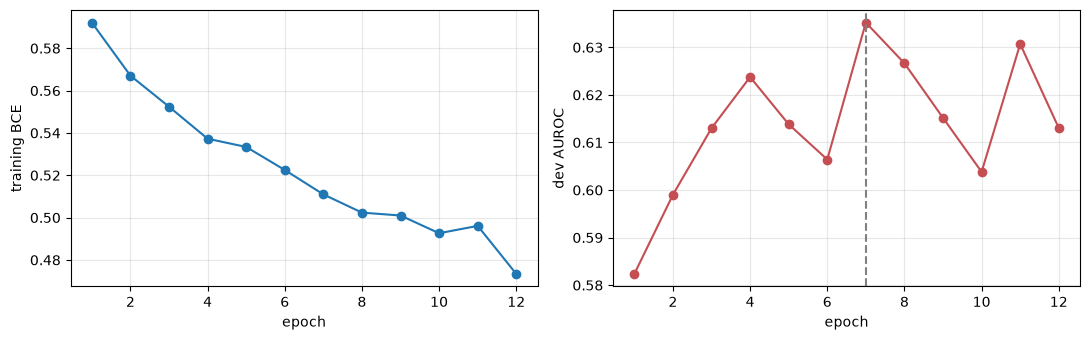

recorded 'MLP on fastText subword average'  dev acc 0.556  test acc 0.553  dev AUROC 0.635  test AUROC 0.621


In [42]:
def train_mlp(X_tr, y_tr, X_de, y_de, hidden=32, lr=0.05, l2=1e-3, batch_size=64,
              max_epochs=60, patience=5, seed=SEED):
    rng = np.random.default_rng(seed)
    params = init_params(X_tr.shape[1], hidden, rng)
    best_params, history = params, {"train_loss": [], "dev_auroc": []}
    for epoch in range(max_epochs):
        order = rng.permutation(len(X_tr))
        for start in range(0, len(order), batch_size):
            batch = order[start:start + batch_size]
            cache = forward(params, X_tr[batch])
            params = sgd_update(params, backward(params, cache, X_tr[batch], y_tr[batch], l2), lr)
        history["train_loss"].append(bce_loss(forward(params, X_tr)["z"], y_tr))
        history["dev_auroc"].append(auroc(y_de, forward(params, X_de)["p"]))
        if history["dev_auroc"][-1] == max(history["dev_auroc"]):
            best_params = {k: v.copy() for k, v in params.items()}
        if should_stop(history["dev_auroc"], patience):
            break
    return best_params, history


t0 = time.time()
mlp_params, mlp_history = train_mlp(X_nn["train"], y_train, X_nn["dev"], y_dev, hidden=16, lr=0.1,
                                    l2=1e-3, max_epochs=15 if FAST else 60)
best_epoch = int(np.argmax(mlp_history["dev_auroc"]))
print(f"Trained in {time.time() - t0:.1f}s: best dev AUROC {max(mlp_history['dev_auroc']):.3f} "
      f"after epoch {best_epoch + 1} of {len(mlp_history['dev_auroc'])}")

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.5))
left.plot(range(1, len(mlp_history["train_loss"]) + 1), mlp_history["train_loss"], "o-")
left.set_xlabel("epoch"), left.set_ylabel("training BCE"), left.grid(alpha=0.3)
right.plot(range(1, len(mlp_history["dev_auroc"]) + 1), mlp_history["dev_auroc"], "o-", color="#C44E52")
right.axvline(best_epoch + 1, color="grey", linestyle="--")
right.set_xlabel("epoch"), right.set_ylabel("dev AUROC"), right.grid(alpha=0.3)
plt.tight_layout()
plt.show()

record("MLP on fastText subword average", forward(mlp_params, X_nn["dev"])["p"],
       forward(mlp_params, X_nn["test"])["p"])


---

# Part 4 — n-gram language models (12 points)

A language model (Lecture 4) assigns a probability to a whole text. With one model for hateful
and one for the other training memes, a meme is classified by which model finds it more
probable. You build both a unigram ($n=1$) and a bigram ($n=2$) version. Texts are padded with
`<bos>` and `<eos>` (the lecture writes `<s>` and `</s>`). Training tokens seen at least twice form the vocabulary; all other tokens
become `<unk>`. $|\mathbb{V}|$ counts the vocabulary plus `<unk>` and `<eos>`.


In [43]:
LM_VOCAB = {w for w, c in token_counts.items() if c >= 2} | {"<unk>", "<eos>"}
V = len(LM_VOCAB)


def map_unknown(docs):
    return [[t if t in LM_VOCAB else "<unk>" for t in doc] for doc in docs]


lm_train, lm_dev, lm_test = map_unknown(train_tokens), map_unknown(dev_tokens), map_unknown(test_tokens)
print(f"|V| = {V}; dev tokens mapped to <unk>: {np.mean([t == '<unk>' for d in lm_dev for t in d]):.1%}")


|V| = 4951; dev tokens mapped to <unk>: 7.8%


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 4.1 — n-gram counts and Laplace smoothing (7 points)

`ngram_counts(tokenized_docs)` pads every document as `["<bos>", *doc, "<eos>"]` and returns
three `Counter`s `(unigrams, bigrams, contexts)`: `unigrams[w]` counts the predicted tokens
(every token after `<bos>`, including `<eos>`), `bigrams[(prev, word)]` how often `word`
follows `prev`, `contexts[prev]` how often `prev` starts a bigram. An empty document gives
the bigram `("<bos>", "<eos>")`.

A language model is a dictionary `lm = {"unigrams": ..., "bigrams": ..., "contexts": ..., "V": ...}`.
`laplace_logprob(prev, word, lm, delta=1.0)` returns the natural logarithm of the
Laplace-smoothed probability (Lecture 4): the bigram probability, or the unigram probability
if `prev` is `None`, with $N$ the total of `lm["unigrams"]`:

$$P(w \mid w_{\text{prev}}) = \frac{\mathrm{count}(w_{\text{prev}}, w) + \delta}{\mathrm{count}(w_{\text{prev}}) + \delta\,|\mathbb{V}|}, \qquad P(w) = \frac{\mathrm{count}(w) + \delta}{N + \delta\,|\mathbb{V}|}$$

`text_logprob(tokens, lm, delta=1.0, order=2)` returns $\log P$ of a whole text: the sum of
`laplace_logprob` over all predicted tokens of the padded text, conditioned on the previous
token if `order=2` and on nothing if `order=1`. Example: with the documents
`[["a", "b"], ["a"]]` and $|\mathbb{V}| = 4$, `text_logprob(["a", "b"], lm)` is
$\log\frac{2+1}{2+4} + \log\frac{1+1}{2+4} + \log\frac{1+1}{1+4}$, and with `order=1` it is
$\log\frac{2+1}{5+4} + \log\frac{1+1}{5+4} + \log\frac{2+1}{5+4}$.

</div>


In [44]:
def ngram_counts(tokenized_docs):
    """(unigrams, bigrams, contexts): Counters over the padded documents."""
    ### YOUR CODE HERE
    unigrams, bigrams, contexts = Counter(), Counter(), Counter()
    for doc in tokenized_docs:
        padded = ["<bos>", *doc, "<eos>"]
        for prev, word in zip(padded[:-1], padded[1:]):
            unigrams[word] += 1
            bigrams[(prev, word)] += 1
            contexts[prev] += 1
    return unigrams, bigrams, contexts


def laplace_logprob(prev, word, lm, delta=1.0):
    """log P(word | prev) with add-delta smoothing; log P(word) if prev is None."""
    ### YOUR CODE HERE
    V_lm = lm["V"]
    if prev is None:
        N = sum(lm["unigrams"].values())
        return float(np.log((lm["unigrams"][word] + delta) / (N + delta * V_lm)))
    return float(np.log((lm["bigrams"][(prev, word)] + delta) / (lm["contexts"][prev] + delta * V_lm)))


def text_logprob(tokens, lm, delta=1.0, order=2):
    """log P of a whole text, padded with <bos> and <eos>, under the unigram or bigram model."""
    ### YOUR CODE HERE
    padded = ["<bos>", *tokens, "<eos>"]
    return float(sum(laplace_logprob(prev if order == 2 else None, word, lm, delta)
                     for prev, word in zip(padded[:-1], padded[1:])))


def make_lm(tokenized_docs):
    unigrams, bigrams, contexts = ngram_counts(tokenized_docs)
    return {"unigrams": unigrams, "bigrams": bigrams, "contexts": contexts, "V": V}


lm_hate = make_lm([d for d, y in zip(lm_train, y_train) if y == 1])
lm_not = make_lm([d for d, y in zip(lm_train, y_train) if y == 0])
print("most frequent bigrams in hateful training memes:", lm_hate["bigrams"].most_common(6))


most frequent bigrams in hateful training memes: [(('<bos>', 'when'), 347), (('<bos>', 'i'), 262), (('when', 'you'), 203), (('<unk>', '<eos>'), 194), (('i', 'm'), 148), (('<unk>', '<unk>'), 134)]


In [45]:
# --- Test 4.1: do not add, remove or modify anything in this cell ---
_u, _b, _c = ngram_counts([["a", "b"], ["a"]])
assert all(isinstance(x, Counter) for x in (_u, _b, _c)), "return three Counters"
assert dict(_u) == {"a": 2, "b": 1, "<eos>": 2}, f"unigrams: {dict(_u)} (<bos> is never predicted)"
assert _b[("<bos>", "a")] == 2 and _b[("a", "b")] == 1 and _b[("b", "<eos>")] == 1 and _b[("a", "<eos>")] == 1
assert sum(_b.values()) == 5, f"5 bigrams in total, got {sum(_b.values())}"
assert _c["<bos>"] == 2 and _c["a"] == 2 and _c["b"] == 1 and _c["<eos>"] == 0, f"contexts: {dict(_c)}"
assert ngram_counts([[]])[1] == Counter({("<bos>", "<eos>"): 1}), "an empty document gives (<bos>, <eos>)"
_lm = {"unigrams": _u, "bigrams": _b, "contexts": _c, "V": 4}
assert abs(laplace_logprob("a", "b", _lm) - np.log(2 / 6)) < 1e-12
assert abs(laplace_logprob("b", "a", _lm, delta=0.5) - np.log(0.5 / 3)) < 1e-12
assert abs(laplace_logprob("zz", "a", _lm) - np.log(1 / 4)) < 1e-12, "an unseen context gives 1/|V|"
assert abs(laplace_logprob(None, "a", _lm) - np.log(3 / 9)) < 1e-12, "unigram: (2 + 1) / (5 + 4)"
_expected = np.log(3 / 6) + np.log(2 / 6) + np.log(2 / 5)
assert abs(text_logprob(["a", "b"], _lm) - _expected) < 1e-12, f"got {text_logprob(['a', 'b'], _lm)}"
assert abs(text_logprob(["a", "b"], _lm, order=1) - np.log(3 / 9 * 2 / 9 * 3 / 9)) < 1e-12
assert abs(text_logprob([], _lm) - np.log(1 / 6)) < 1e-12
assert sum(lm_hate["contexts"].values()) == sum(lm_hate["bigrams"].values()) == sum(lm_hate["unigrams"].values())
print("Task 4.1 passed")


Task 4.1 passed


Three texts sampled from each class bigram model (unsmoothed counts): locally fluent,
globally incoherent (Lecture 4).


In [46]:
def sample_text(lm, rng, max_len=20):
    prev, words = "<bos>", []
    followers = {}
    for (p, w), c in lm["bigrams"].items():
        followers.setdefault(p, []).append((w, c))
    while len(words) < max_len:
        options, counts = zip(*followers[prev])
        prev = options[rng.choice(len(options), p=np.array(counts) / sum(counts))]
        if prev == "<eos>":
            break
        words.append(prev)
    return " ".join(words)


_rng = np.random.default_rng(SEED)
for name, lm in [("hateful LM", lm_hate), ("not-hateful LM", lm_not)]:
    for _ in range(3):
        print(f"{name:<15} {sample_text(lm, _rng)}")


hateful LM      stop cause of all fucking cotton here somewhere else
hateful LM      the old little muslim girlfriend i only for land and everyone told that people into a traitor and the owners
hateful LM      feeling pretty cringe
not-hateful LM  <unk>
not-hateful LM  what people
not-hateful LM  on <unk> white women


<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">TASK &middot; GRADED AUTOMATICALLY</span>

## Task 4.2 — Two language models as one classifier (5 points)

By Bayes' rule, the log-odds that a text $x$ is hateful are

$$\mathrm{score}(x) = \log P(x \mid \text{hateful LM}) - \log P(x \mid \text{not-hateful LM}) + \log\frac{P(y=1)}{P(y=0)}$$

and the text is classified hateful if the score is at least 0.

Write `log_prior_ratio(y)`: $\log(n_1 / n_0)$ for an array of training labels, as a `float`.

Write `class_lm_score(tokens, lm_hate, lm_not, prior, delta=1.0, order=2)`: the score above,
with `prior` the value of `log_prior_ratio` and `text_logprob` for both models, using `delta`
and `order`.

</div>


In [47]:
def log_prior_ratio(y):
    """log(n_1 / n_0) of the training labels."""
    ### YOUR CODE HERE
    y = np.asarray(y)
    return float(np.log(np.sum(y == 1) / np.sum(y == 0)))


def class_lm_score(tokens, lm_hate, lm_not, prior, delta=1.0, order=2):
    """Log-odds that the text is hateful under the two class language models."""
    ### YOUR CODE HERE
    return float(text_logprob(tokens, lm_hate, delta, order)
                 - text_logprob(tokens, lm_not, delta, order) + prior)


PRIOR = log_prior_ratio(y_train)
print(f"log prior ratio: {PRIOR:.3f}")


log prior ratio: -0.596


In [48]:
# --- Test 4.2: do not add, remove or modify anything in this cell ---
assert abs(log_prior_ratio(np.array([1, 0, 0, 0])) - np.log(1 / 3)) < 1e-12
assert isinstance(log_prior_ratio([1, 1, 0]), float)
assert abs(PRIOR - np.log(3019 / 5481)) < 1e-9
_lh, _ln = make_lm([["x", "y"]]), make_lm([["y", "x"]])
_lh["V"] = _ln["V"] = 3
_s = class_lm_score(["x", "y"], _lh, _ln, 0.0)
assert abs(_s - (text_logprob(["x", "y"], _lh) - text_logprob(["x", "y"], _ln))) < 1e-12
assert _s > 0, "a word order seen only in the hateful corpus must score > 0 under the bigram models"
assert abs(class_lm_score(["x", "y"], _lh, _ln, 0.0, order=1)) < 1e-12, "same words, so the unigram models tie"
assert abs(class_lm_score(["x", "y"], _lh, _ln, -2.0, delta=0.1)
           - (text_logprob(["x", "y"], _lh, 0.1) - text_logprob(["x", "y"], _ln, 0.1) - 2.0)) < 1e-12
print("Task 4.2 passed")


Task 4.2 passed


### Unigram and bigram classifiers on the leaderboard (nothing to implement)

Both use the lecture's $\delta = 1$. Not in the lecture: the unigram version is a
multinomial **Naive Bayes** classifier, a bag of words with probabilities. For the bigram
version, Laplace smoothing with $|\mathbb{V}|$ in the thousands moves most of a sparse bigram
row's probability mass onto unseen bigrams, and the smaller hateful corpus has the sparser rows.


In [49]:
LM_NAMES = {1: "class unigram LMs (Naive Bayes)", 2: "class bigram LMs"}
for order, name in LM_NAMES.items():
    dev_lm = np.array([class_lm_score(d, lm_hate, lm_not, PRIOR, order=order) for d in lm_dev])
    test_lm = np.array([class_lm_score(d, lm_hate, lm_not, PRIOR, order=order) for d in lm_test])
    print(f"{name}: dev memes classified hateful {np.mean(dev_lm >= 0):.1%}")
    record(name, dev_lm, test_lm, threshold=0.0)


class unigram LMs (Naive Bayes): dev memes classified hateful 25.4%
recorded 'class unigram LMs (Naive Bayes)'  dev acc 0.564  test acc 0.583  dev AUROC 0.611  test AUROC 0.623
class bigram LMs: dev memes classified hateful 7.6%
recorded 'class bigram LMs'                 dev acc 0.530  test acc 0.548  dev AUROC 0.506  test AUROC 0.512


---

# Part 5 — The leaderboard (0 points + written block 2)

The standard error of an accuracy near 0.6 on 1000 memes is
$\sqrt{0.6 \cdot 0.4 / 1000} \approx 0.015$. The last two columns are a 95% bootstrap interval
for each model's test AUROC difference to the bag of words (test memes resampled with
replacement).


standard error of an accuracy of 0.6: dev 0.022, test 0.015


,dev_accuracy,test_accuracy,dev_auroc,test_auroc,test_acc_vs_A1,test_auroc_vs_A1,auroc_diff_low,auroc_diff_high
model,,,,,,,,
A1 bag of words (tf-idf),0.548,0.568,0.621,0.636,0.000,0.000,0.000,0.000
LogReg on PPMI average (C=0.01),0.536,0.548,0.625,0.623,-0.020,-0.013,-0.047,0.020
LogReg on fastText whole-word average (C=10),0.532,0.549,0.616,0.620,-0.019,-0.016,-0.051,0.021
LogReg on fastText subword average (C=10),0.534,0.550,0.619,0.620,-0.018,-0.016,-0.051,0.021
MLP on fastText subword average,0.556,0.553,0.635,0.621,-0.015,-0.015,-0.048,0.022
class unigram LMs (Naive Bayes),0.564,0.583,0.611,0.623,0.015,-0.013,-0.040,0.015
class bigram LMs,0.530,0.548,0.506,0.512,-0.020,-0.124,-0.163,-0.089


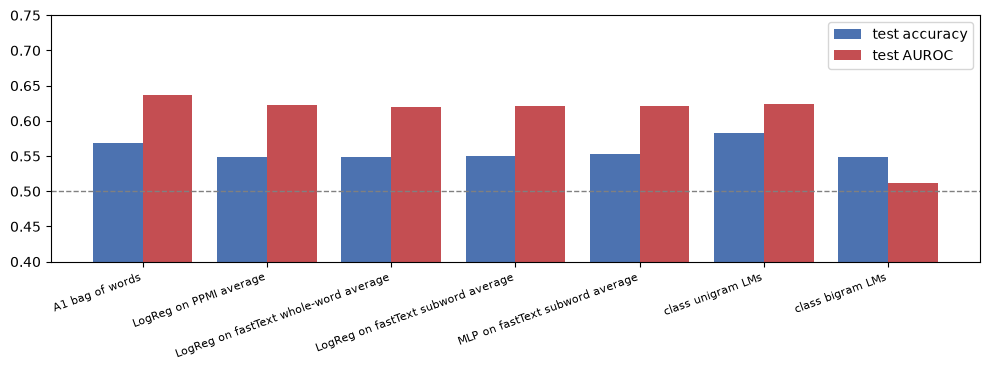

In [50]:
_rng = np.random.default_rng(SEED)
n_boot = 200 if FAST else 1000
boot = [_rng.integers(0, len(y_test), len(y_test)) for _ in range(n_boot)]
base_name = "A1 bag of words (tf-idf)"
base_test = SCORES[base_name][1]
rows = []
for name, row in LEADERBOARD.items():
    test_scores = SCORES[name][1]
    # roc_auc_score from scikit-learn computes the same value as your auroc, only faster.
    diffs = [roc_auc_score(y_test[b], test_scores[b]) - roc_auc_score(y_test[b], base_test[b]) for b in boot]
    rows.append({"model": name, **row,
                 "test_acc_vs_A1": row["test_accuracy"] - LEADERBOARD[base_name]["test_accuracy"],
                 "test_auroc_vs_A1": row["test_auroc"] - LEADERBOARD[base_name]["test_auroc"],
                 "auroc_diff_low": np.percentile(diffs, 2.5), "auroc_diff_high": np.percentile(diffs, 97.5)})
board = pd.DataFrame(rows).set_index("model")
print(f"standard error of an accuracy of 0.6: dev {np.sqrt(0.24 / len(y_dev)):.3f}, "
      f"test {np.sqrt(0.24 / len(y_test)):.3f}")
display(board.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(board))
ax.bar(x - 0.2, board["test_accuracy"], 0.4, label="test accuracy", color="#4C72B0")
ax.bar(x + 0.2, board["test_auroc"], 0.4, label="test AUROC", color="#C44E52")
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(x, [n.split(" (")[0] for n in board.index], rotation=20, ha="right", fontsize=8)
ax.set_ylim(0.4, 0.75)
ax.legend()
plt.tight_layout()
plt.show()


### Where the language models and the bag of words disagree (nothing to implement)

Dev memes on which the bag of words and the class LM with the higher dev AUROC decide
differently, with the tokens (unigram) or bigrams that moved the LM score most: $\log P$ under
the hateful minus the not-hateful model.


In [51]:
LM_ORDER = max(LM_NAMES, key=lambda o: LEADERBOARD[LM_NAMES[o]]["dev_auroc"])
lm_name = LM_NAMES[LM_ORDER]
lm_dev_scores, bow_dev_scores = SCORES[lm_name][0], SCORES[base_name][0]
lm_says, bow_says = (lm_dev_scores >= 0).astype(int), (bow_dev_scores >= 0.5).astype(int)
disagree = np.where(lm_says != bow_says)[0]
print(f"{lm_name}: {len(disagree)} of 500 dev memes are classified differently from the bag of words.\n")


def lm_contributions(tokens, order=LM_ORDER):
    padded = ["<bos>", *tokens, "<eos>"]
    parts = [(f"{p} {w}" if order == 2 else w,
              laplace_logprob(p if order == 2 else None, w, lm_hate)
              - laplace_logprob(p if order == 2 else None, w, lm_not))
             for p, w in zip(padded[:-1], padded[1:])]
    return sorted(parts, key=lambda kv: -abs(kv[1]))


for says in (1, 0):
    group = disagree[lm_says[disagree] == says]
    for i in group[np.argsort(-np.abs(lm_dev_scores[group]))][:3]:
        print(f"dev meme {i}, true label {y_dev[i]}: {df_dev['text'].iloc[i]}")
        print(f"  LM score {lm_dev_scores[i]:+.2f} -> {lm_says[i]}   "
              f"bag of words P(hateful) {bow_dev_scores[i]:.2f} -> {bow_says[i]}")
        print("  strongest:", ", ".join(f"'{t}' {c:+.2f}" for t, c in lm_contributions(lm_dev[i])[:4]))


class unigram LMs (Naive Bayes): 94 of 500 dev memes are classified differently from the bag of words.

dev meme 24, true label 1: whatsthe difference between heroin and i? cops think twice before shooting heroin
  LM score +3.24 -> 1   bag of words P(hateful) 0.34 -> 0
  strongest: 'between' +1.14, 'difference' +0.82, 'heroin' +0.71, 'heroin' +0.71
dev meme 21, true label 1: white people on cinco de mayo vs. every other day
  LM score +3.08 -> 1   bag of words P(hateful) 0.28 -> 0
  strongest: 'cinco' +1.34, 'de' +1.34, 'white' +1.01, 'mayo' +0.71
dev meme 434, true label 0: are you a boy or a girl i'm non binary
  LM score +2.89 -> 1   bag of words P(hateful) 0.21 -> 0
  strongest: 'non' +1.67, 'binary' +1.11, 'boy' +0.42, 'or' +0.32
dev meme 85, true label 0: me and my kids are going to rob this country blind at the expense of the very people that voted for me. and they're going to love it. believe me! bigly!
  LM score -3.61 -> 0   bag of words P(hateful) 0.89 -> 1
  strongest: 'ro

<div style="background:#FFF4E5;border:1px solid #E8A33D;border-left:9px solid #E8A33D;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#9C5A00;letter-spacing:.05em;font-size:.9em">WRITTEN ANSWER &middot; GRADED BY A HUMAN</span>

This block gets one weight between **0.0** and **1.0**. The average of the two written weights multiplies your coding points (see *Grading* at the top). Quote *your* numbers and examples from this notebook; statements that would be true of any dataset score 0.0.

## Written block 2 — Did learning beat counting? (weight 0.0–1.0)

Two questions, 3 to 6 sentences each.

### Question 1 — The leaderboard

Which models beat the Assignment 1 bag of words on test accuracy, which on test AUROC, and by
how much? Is the best difference large given 500 dev and 1000 test memes? Use the printed
standard error and bootstrap interval.

### Question 2 — One disagreement

Pick one dev meme from the list above; copy its text, true label, both decisions and its
strongest tokens or bigrams. Why did the language models score it this way, and which model
is right about this meme?

</div>


<div style="background:#EEF5FB;border:1px solid #4C72B0;border-left:9px solid #4C72B0;border-radius:6px;padding:6px 20px 14px 20px;margin:14px 0 14px 0;color:#1a1a1a">

<span style="font-weight:700;color:#2A5183;letter-spacing:.05em;font-size:.9em">YOUR ANSWERS</span> &mdash; replace every *(write here)* line and keep the headings.

### Written block 2 — question 1  (the leaderboard)

**Better than A1 on test accuracy / on test AUROC:** _(write here)_

_(write here)_

### Written block 2 — question 2  (one disagreement)

**Meme, true label, both decisions, strongest tokens or bigrams:** _(write here)_

_(write here)_

</div>


---

## Submission check

Run the next cell last. It checks completeness, not your grade.


In [52]:
# --- Submission check: do not add, remove or modify anything in this cell ---
REQUIRED_FUNCTIONS = [
    "auroc", "cooccurrence_matrix", "ppmi_matrix", "cosine", "nearest_neighbours",
    "sgns_loss_and_grads", "average_vector", "forward", "bce_loss", "backward",
    "sgd_update", "should_stop", "ngram_counts", "laplace_logprob", "text_logprob",
    "log_prior_ratio", "class_lm_score",
]
problems = [f"the function {name}() is missing" for name in REQUIRED_FUNCTIONS
            if not callable(globals().get(name))]
if len(LEADERBOARD) < 7:
    problems.append(f"the leaderboard has {len(LEADERBOARD)} of 7 models; did every cell run?")
if problems:
    print("SUBMISSION NOT READY:\n")
    for problem in problems:
        print(f"  - {problem}")
    raise SystemExit("Fix the points above, then run all cells again.")

print("Submission check passed.\n")
print("  Save this notebook as:  assignment_02_<matriculation 1>_<matriculation 2>.ipynb")
print("  One file per team, uploaded by one team member.")
print("\n  Not checked here: the written blocks (written blocks 1 and 2).")
print("  Make sure every '_(write here)_' is replaced.")


Submission check passed.

  Save this notebook as:  assignment_02_<matriculation 1>_<matriculation 2>.ipynb
  One file per team, uploaded by one team member.

  Not checked here: the written blocks (written blocks 1 and 2).
  Make sure every '_(write here)_' is replaced.


---

## Before you submit

Restart the kernel and run all cells; every test prints `Task N.N passed` and the submission
check passes. Answer both written blocks with numbers your notebook printed, save with
outputs, and upload. Assignment 3 replaces averaged word vectors with attention, which reads
the words in order, and adds the picture.
